In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy import stats

sns.set_theme(style="whitegrid")

print("MACHINEGUARD - Practical Work 2")
print("Libraries loaded successfully!")


MACHINEGUARD - Practical Work 2
Libraries loaded successfully!


In [2]:

project_dir = Path.cwd().resolve()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

file_path = project_dir / "data" / "raw" / "ai4i2020.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:

dirty_df = df.copy()

rng = np.random.default_rng(42)

# Add missing values to 5% of temperature records
missing_rows = rng.choice(
    dirty_df.index,
    size=500,
    replace=False
)

dirty_df.loc[missing_rows, "Air temperature [K]"] = np.nan

# Add 100 duplicate records
duplicate_rows = dirty_df.sample(
    n=100,
    random_state=42
)

dirty_df = pd.concat(
    [dirty_df, duplicate_rows],
    ignore_index=True
)

# Add 20 invalid negative rotational speeds
invalid_rows = rng.choice(
    dirty_df.index,
    size=20,
    replace=False
)

dirty_df.loc[
    invalid_rows,
    "Rotational speed [rpm]"
] = -100

print("Original dataset:", df.shape)
print("Modified dataset:", dirty_df.shape)

print("\nMissing values:")
print(dirty_df.isnull().sum())

print("\nDuplicate rows:", dirty_df.duplicated().sum())

print(
    "Negative rotational speeds:",
    (dirty_df["Rotational speed [rpm]"] < 0).sum()
)


Original dataset: (10000, 14)
Modified dataset: (10100, 14)

Missing values:
UDI                          0
Product ID                   0
Type                         0
Air temperature [K]        503
Process temperature [K]      0
Rotational speed [rpm]       0
Torque [Nm]                  0
Tool wear [min]              0
Machine failure              0
TWF                          0
HDF                          0
PWF                          0
OSF                          0
RNF                          0
dtype: int64

Duplicate rows: 100
Negative rotational speeds: 20


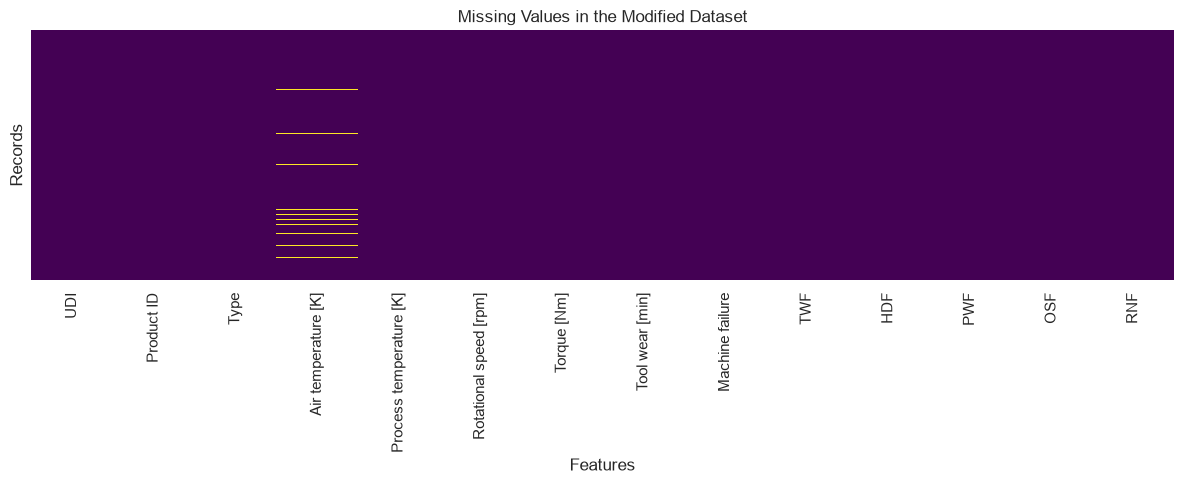

In [4]:

plt.figure(figsize=(12, 5))

sns.heatmap(
    dirty_df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values in the Modified Dataset")
plt.xlabel("Features")
plt.ylabel("Records")

plt.tight_layout()
plt.show()


### Missing Values Analysis

The original AI4I 2020 dataset contains no missing values or duplicate records.

For educational purposes, a separate modified copy was created with artificially introduced missing values, duplicate records, and invalid rotational speeds.

The missing-value heatmap shows that missing values are concentrated in the Air temperature [K] column.

These problems must be addressed during data preprocessing. The original dataset remains unchanged.

In [5]:

output_path = project_dir / "data" / "processed" / "ai4i_dirty.csv"

output_path.parent.mkdir(parents=True, exist_ok=True)

dirty_df.to_csv(output_path, index=False)

print("Modified dataset saved successfully!")
print(output_path)


Modified dataset saved successfully!
/Users/aolimeow/Documents/ML-Projects/machineguard-ml/data/processed/ai4i_dirty.csv


Machine failure distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure percentage: 3.39%


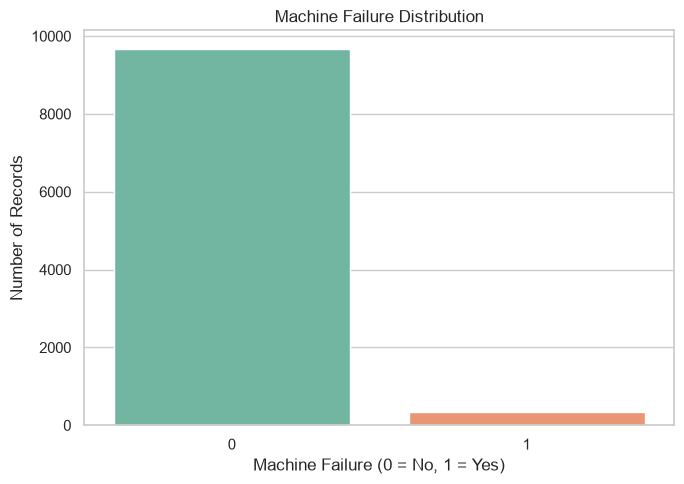

In [6]:

failure_counts = df["Machine failure"].value_counts().sort_index()

print("Machine failure distribution:")
print(failure_counts)

failure_percentage = df["Machine failure"].mean() * 100

print(f"\nFailure percentage: {failure_percentage:.2f}%")

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Machine failure",
    hue="Machine failure",
    palette="Set2",
    legend=False
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()


### Machine Failure Distribution — Analysis

The dataset contains 9,661 records without machine failure and 339 records with machine failure.

The failure rate is 3.39%, indicating a strong class imbalance.

This imbalance is important because a classification model may achieve high accuracy by predicting the majority class.

Therefore, precision, recall, F1-score, and the confusion matrix should be considered during model evaluation.

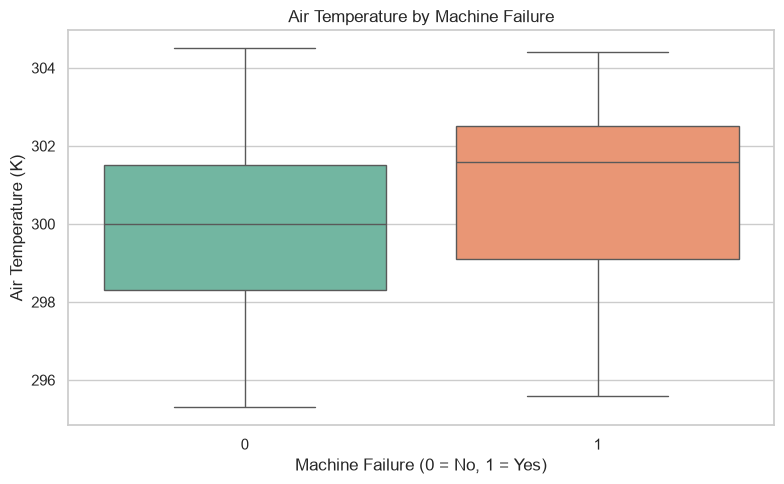

In [7]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Air temperature [K]",
    hue="Machine failure",
    palette="Set2",
    legend=False
)

plt.title("Air Temperature by Machine Failure")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Air Temperature (K)")

plt.tight_layout()
plt.show()


### Air Temperature — Analysis

The boxplot compares air temperature distributions for machines with and without recorded failures.

The visualization helps identify possible differences in median temperature, variability, and outliers between the two groups.

A statistical test is required to determine whether the observed difference is statistically significant. Any association should not be interpreted as proof of causation.

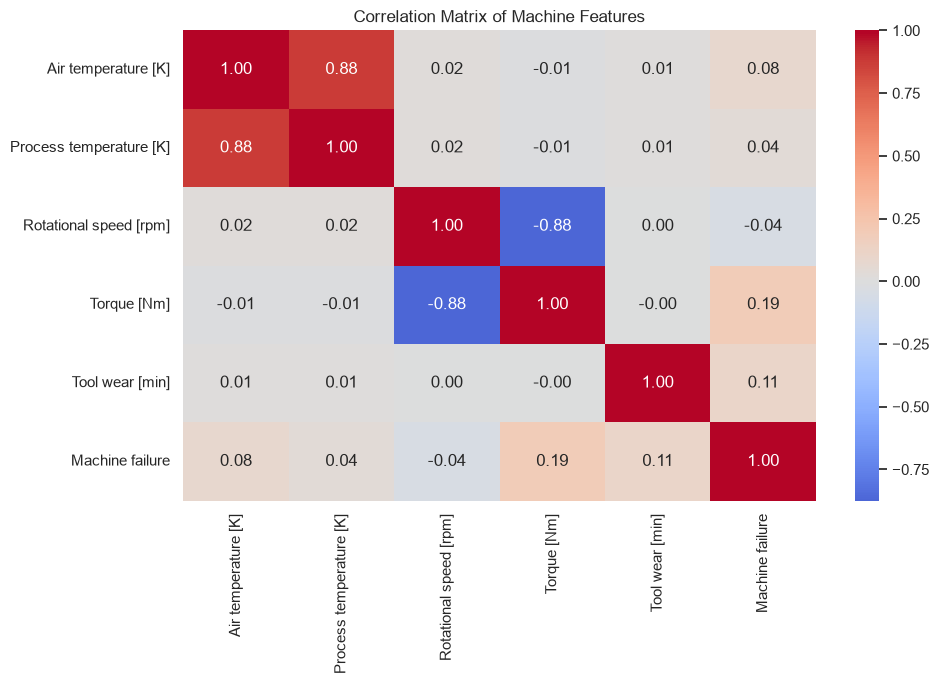

In [8]:

features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Machine failure"
]

correlation_matrix = df[features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Matrix of Machine Features")

plt.tight_layout()
plt.show()


### Correlation Analysis

The correlation matrix illustrates linear relationships between numerical machine operating features and the machine failure target.

Correlation coefficients range from -1 to +1. Values close to zero indicate weak linear relationships, while values closer to -1 or +1 indicate stronger linear relationships.

The analysis can help identify potentially useful predictors and highly correlated input features.

Correlation alone does not establish causation, and weak individual correlations do not necessarily mean that a feature is unsuitable for machine learning.

In [9]:

hypotheses = {
    "H1: Air temperature": "Air temperature [K]",
    "H2: Torque": "Torque [Nm]",
    "H3: Rotational speed": "Rotational speed [rpm]"
}

results = []

for hypothesis, column in hypotheses.items():

    no_failure = df.loc[
        df["Machine failure"] == 0, column
    ].dropna()

    failure = df.loc[
        df["Machine failure"] == 1, column
    ].dropna()

    statistic, p_value = stats.mannwhitneyu(
        no_failure,
        failure,
        alternative="two-sided"
    )

    results.append({
        "Hypothesis": hypothesis,
        "Median (No Failure)": no_failure.median(),
        "Median (Failure)": failure.median(),
        "U Statistic": statistic,
        "P-value": p_value
    })

results_df = pd.DataFrame(results)

display(results_df)


,Hypothesis,Median (No Failure),Median (Failure),U Statistic,P-value
0,H1: Air temperature,300.0,301.6,1202819.0,8.656108e-17
1,H2: Torque,39.9,53.7,752493.0,2.262232e-64
2,H3: Rotational speed,1507.0,1365.0,2510959.0,9.706908e-63


In [10]:

alpha = 0.05

for _, row in results_df.iterrows():

    print(row["Hypothesis"])
    print(f"P-value: {row['P-value']:.6g}")

    if row["P-value"] < alpha:
        print("Result: Statistically significant difference")
    else:
        print("Result: No statistically significant difference detected")

    print("-" * 45)


H1: Air temperature
P-value: 8.65611e-17
Result: Statistically significant difference
---------------------------------------------
H2: Torque
P-value: 2.26223e-64
Result: Statistically significant difference
---------------------------------------------
H3: Rotational speed
P-value: 9.70691e-63
Result: Statistically significant difference
---------------------------------------------


### Statistical Hypothesis Testing

Three hypotheses were tested to investigate the relationship between machine operating conditions and recorded machine failures.

The Mann–Whitney U test was applied to compare air temperature, torque, and rotational speed between failed and non-failed machines.

The significance level was set to 0.05.

The results should be interpreted using the calculated p-values and group medians. A statistically significant result provides evidence of a difference between the groups, but does not prove a causal relationship.

Since three statistical tests were performed, multiple-testing correction should also be considered before drawing final conclusions.

### Data Leakage Risks

Data leakage occurs when information that would not be available at prediction time is used to train a machine learning model.

In the AI4I 2020 dataset, the following columns present potential leakage risks:

- **TWF:** Tool Wear Failure
- **HDF:** Heat Dissipation Failure
- **PWF:** Power Failure
- **OSF:** Overstrain Failure
- **RNF:** Random Failure

These columns identify specific failure outcomes and should not be used as input features when predicting the overall Machine failure target.

The UDI and Product ID columns are identifiers rather than direct machine operating measurements and will also be excluded from the initial model.

Potentially useful input features include air temperature, process temperature, rotational speed, torque, tool wear, and product type.

These features are selected based on their operational relevance. Their actual predictive value must be verified through model training and evaluation.

In [11]:

alpha = 0.05

number_of_tests = len(results_df)
adjusted_alpha = alpha / number_of_tests

results_df["Adjusted p-value"] = np.minimum(
    results_df["P-value"] * number_of_tests,
    1.0
)

results_df["Significant after correction"] = (
    results_df["Adjusted p-value"] < alpha
)

print(f"Original alpha: {alpha}")
print(f"Bonferroni adjusted threshold: {adjusted_alpha:.4f}")

display(results_df)



Original alpha: 0.05
Bonferroni adjusted threshold: 0.0167


,Hypothesis,Median (No Failure),Median (Failure),U Statistic,P-value,Adjusted p-value,Significant after correction
0,H1: Air temperature,300.0,301.6,1202819.0,8.656108e-17,2.596832e-16,True
1,H2: Torque,39.9,53.7,752493.0,2.262232e-64,6.786697e-64,True
2,H3: Rotational speed,1507.0,1365.0,2510959.0,9.706908e-63,2.912072e-62,True


### Multiple Hypothesis Testing Correction

The Bonferroni correction was applied to control the risk of false-positive results when testing three hypotheses.

The original significance level was 0.05, and the adjusted significance threshold was approximately 0.0167.

Hypotheses with adjusted p-values below 0.05 are considered statistically significant after correction.

This procedure provides a more conservative interpretation of the statistical tests.

In [12]:

quality_report = pd.DataFrame({
    "Data Quality Issue": [
        "Missing air temperature values",
        "Duplicate records",
        "Negative rotational speed values"
    ],
    "Original Dataset": [
        df["Air temperature [K]"].isna().sum(),
        df.duplicated().sum(),
        (df["Rotational speed [rpm]"] < 0).sum()
    ],
    "Modified Dataset": [
        dirty_df["Air temperature [K]"].isna().sum(),
        dirty_df.duplicated().sum(),
        (dirty_df["Rotational speed [rpm]"] < 0).sum()
    ]
})

display(quality_report)


,Data Quality Issue,Original Dataset,Modified Dataset
0,Missing air temperature values,0,503
1,Duplicate records,0,100
2,Negative rotational speed values,0,20


### Data Quality Assessment

The original AI4I 2020 dataset does not contain missing values, duplicate records, or negative rotational speeds.

A separate modified dataset was created to simulate realistic data quality problems.

Three types of problems were introduced:

1. Missing values in air temperature measurements.
2. Duplicate observations.
3. Invalid negative rotational speed measurements.

These issues can affect statistical analysis and machine learning performance.

Missing values may require imputation, duplicate records should be investigated before removal, and physically invalid measurements require correction or exclusion.

The modified dataset is used only for educational data quality experiments. The original dataset remains unchanged.

In [13]:

summary = results_df[
    [
        "Hypothesis",
        "Median (No Failure)",
        "Median (Failure)",
        "P-value",
        "Adjusted p-value",
        "Significant after correction"
    ]
].copy()

summary["Conclusion"] = np.where(
    summary["Significant after correction"],
    "Significant difference detected",
    "No significant difference detected"
)

display(summary)


,Hypothesis,Median (No Failure),Median (Failure),P-value,Adjusted p-value,Significant after correction,Conclusion
0,H1: Air temperature,300.0,301.6,8.656108e-17,2.596832e-16,True,Significant difference detected
1,H2: Torque,39.9,53.7,2.262232e-64,6.786697e-64,True,Significant difference detected
2,H3: Rotational speed,1507.0,1365.0,9.706908e-63,2.912072e-62,True,Significant difference detected


## Final Conclusions

### Practical Work 2: Exploratory Data Analysis

The exploratory data analysis of the AI4I 2020 Predictive Maintenance dataset was conducted as part of the MACHINEGUARD project.

**1. Dataset Characteristics**

The dataset contains 10,000 observations and 14 columns. The target variable is Machine failure.

Only 3.39% of observations represent machine failures, indicating a strong class imbalance. This should be considered when developing classification models.

**2. Data Quality**

The original dataset contains no missing values or duplicate records.

For educational purposes, a separate dataset was created with artificially introduced missing values, duplicate observations, and invalid rotational speeds.

The analysis demonstrates the importance of identifying data quality issues before training machine learning models.

**3. Data Visualization**

Several visualization techniques were used, including a missing-value heatmap, count plot, boxplot, and correlation heatmap.

These visualizations help describe class distribution, compare machine operating conditions, and investigate relationships between numerical variables.

**4. Statistical Hypothesis Testing**

Three statistical hypotheses were examined using the Mann–Whitney U test.

The Bonferroni correction was applied to account for multiple comparisons.

The statistical results should be interpreted using the calculated p-values, adjusted p-values, and group medians.

**5. Data Leakage**

The failure-type indicators TWF, HDF, PWF, OSF, and RNF were identified as potential sources of target leakage.

These columns must be excluded from predictors when developing a model for the overall Machine failure target.

**6. Expected Important Features**

Air temperature, process temperature, rotational speed, torque, tool wear, and product type are potential predictors based on their operational meaning.

Their predictive importance will be evaluated in subsequent practical works.

**7. Next Steps**

The next stage of the MACHINEGUARD project will focus on data preprocessing, custom transformers, and reproducible machine learning pipelines.

The results of this exploratory analysis will guide feature selection and preprocessing decisions.